# Лабораторная работа: Динамические системы, устойчивость и бифуркации
**Вариант 15:** $k = 1.8,\ \ell = 0.6,\ a = 0.24,\ b = 0.10$

## Задание 1. Модель Лотки–Вольтерры

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['axes.grid'] = True

k, l, a, b = 1.8, 0.6, 0.24, 0.10
x0, y0 = 10.0, 5.0
T, h = 100.0, 0.001

### 1. Численное интегрирование (метод Эйлера)

$$x_{i+1}=x_i+h\,(kx_i-ax_iy_i),\qquad y_{i+1}=y_i+h\,(-\ell y_i+bx_iy_i),\qquad h=0.001$$

In [2]:
n = int(round(T/h))
t = np.linspace(0, T, n + 1)
x = np.empty(n + 1); y = np.empty(n + 1)
x[0], y[0] = x0, y0

for i in range(n):
    x[i+1] = x[i] + h*(k*x[i] - a*x[i]*y[i])
    y[i+1] = y[i] + h*(-l*y[i] + b*x[i]*y[i])

### 2. Графики $x(t)$, $y(t)$ и фазовый портрет

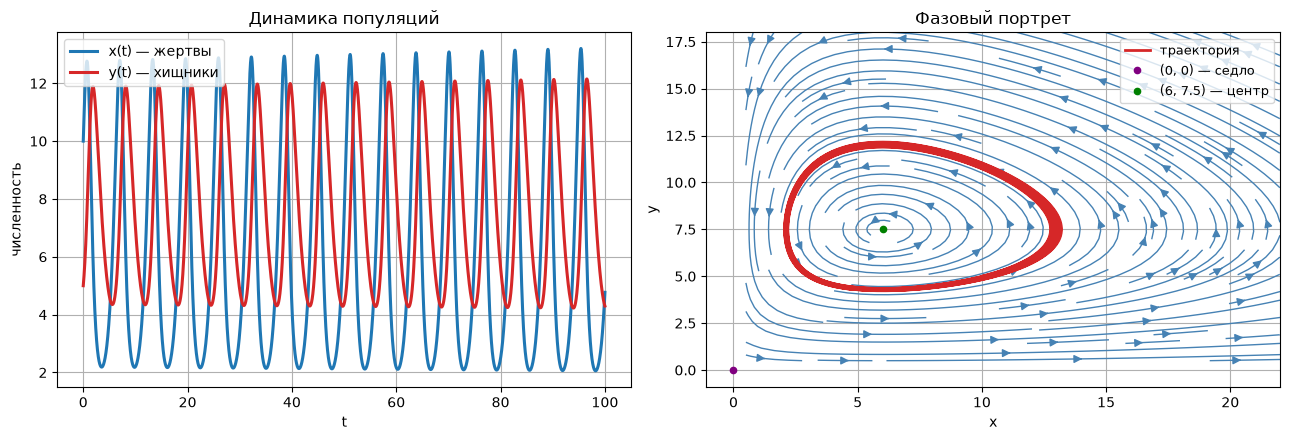

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(t, x, color='#1f77b4', lw=2.2, label='x(t) — жертвы')
ax[0].plot(t, y, color='#d62728', lw=2.2, label='y(t) — хищники')
ax[0].set_xlabel('t')
ax[0].set_ylabel('численность')
ax[0].set_title('Динамика популяций'); 
ax[0].legend()
ax[0].grid(True)

xs, ys = x0_s, y0_s = (l/b), (k/a)
X, Y = np.meshgrid(np.linspace(0.5, 22, 22), np.linspace(0.5, 18, 22))
U = k*X - a*X*Y
W = -l*Y + b*X*Y

ax[1].streamplot(X, Y, U, W, color='steelblue', density=1.3,
                 linewidth=1.0, arrowsize=1.2)
ax[1].plot(x, y, color='#d62728', lw=2.0, label='траектория')
ax[1].plot(0, 0, '.', color='purple', ms=9, label='(0, 0) — седло')
ax[1].plot(xs, ys, '.', color='green', ms=9, label=f'({xs:.0f}, {ys:.1f}) — центр')

ax[1].set_xlabel('x')
ax[1].set_ylabel('y')
ax[1].set_title('Фазовый портрет')
ax[1].legend(loc='upper right', fontsize=9)
ax[1].grid(True)

plt.tight_layout()
plt.show()

**Вывод.** Численности жертв и хищников колеблются периодически с запаздыванием по фазе: рост жертв ведёт к росту хищников, затем жертвы убывают, и хищники вслед за ними. На фазовой плоскости траектория — замкнутая кривая вокруг точки $(\ell/b,\,k/a)=(6;\,7.5)$. (Небольшое раскручивание спирали связано с погрешностью метода Эйлера, см. п. 4.)

### 3. Тип стационарных точек (матрица Якоби)

$$J=\begin{pmatrix}k-ay & -ax\\ by & -\ell+bx\end{pmatrix}$$

In [4]:
def jac(px, py):
    return np.array([[k - a*py, -a*px],
                     [b*py, -l + b*px]])

for name, (px, py) in {'(0, 0)': (0, 0), '(l/b, k/a)': (l/b, k/a)}.items():
    J = jac(px, py)
    ev = np.linalg.eigvals(J)
    print(f'Точка {name} = ({px:.3g}, {py:.3g})')
    print('J =\n', J)
    print('собственные значения:', ev, '\n')

Точка (0, 0) = (0, 0)
J =
 [[ 1.8 -0. ]
 [ 0.  -0.6]]
собственные значения: [ 1.8+0.j -0.6+0.j] 

Точка (l/b, k/a) = (6, 7.5)
J =
 [[ 0.   -1.44]
 [ 0.75  0.  ]]
собственные значения: [0.+1.03923048j 0.-1.03923048j] 



**Вывод.**
- $(0,0)$: $J=\mathrm{diag}(k,-\ell)$, $\lambda_1=1.8>0$, $\lambda_2=-0.6<0$ — **седло** (неустойчиво).
- $(\ell/b,\,k/a)=(6;\,7.5)$: $J=\begin{pmatrix}0&-1.44\\0.75&0\end{pmatrix}$, $\lambda_{1,2}=\pm i\sqrt{k\ell}=\pm 1.039\,i$ — чисто мнимые, **центр** (линейный анализ не даёт асимптотической устойчивости; вокруг точки — замкнутые орбиты). Период малых колебаний $2\pi/\sqrt{k\ell}\approx 6.05$.

### 4. Первый интеграл $V(x,y)=bx-\ell\ln x+ay-k\ln y$

max |dV/dt| (аналитически) = 3.608224830031759e-16
V(0) = -2.078539,  V(T) = -2.053587
max |V(t) - V(0)| = 0.0250
относительное изменение = 1.20%


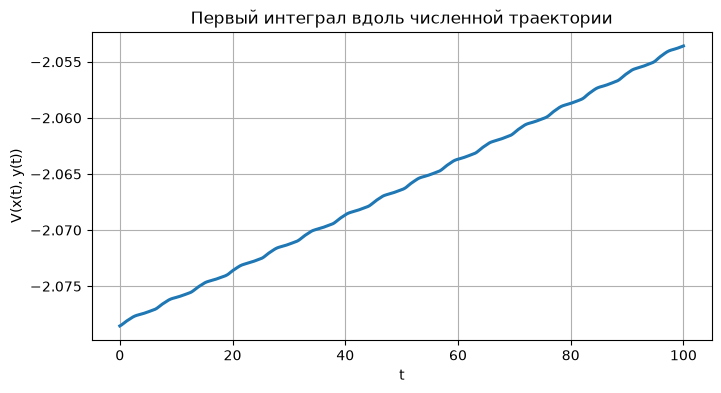

In [5]:
V = b*x - l*np.log(x) + a*y - k*np.log(y)

# dV/dt = (b - l/x)*x' + (a - k/y)*y'
dx = k*x - a*x*y
dy = -l*y + b*x*y
dVdt = (b - l/x)*dx + (a - k/y)*dy
print('max |dV/dt| (аналитически) =', np.abs(dVdt).max())

print(f'V(0) = {V[0]:.6f},  V(T) = {V[-1]:.6f}')
print(f'max |V(t) - V(0)| = {np.abs(V - V[0]).max():.4f}')
print(f'относительное изменение = {np.abs(V - V[0]).max()/abs(V[0]):.2%}')

plt.figure(figsize=(8, 4))
plt.plot(t, V, color='#1f77b4', lw=2.2)
plt.xlabel('t'); plt.ylabel('V(x(t), y(t))')
plt.title('Первый интеграл вдоль численной траектории'); plt.show()

**Аналитическая проверка.** Подставляя уравнения системы:

$$\frac{dV}{dt}=\Big(b-\frac{\ell}{x}\Big)x(k-ay)+\Big(a-\frac{k}{y}\Big)y(-\ell+bx)
=(bx-\ell)(k-ay)+(ay-k)(bx-\ell)=0,$$

т.е. $V$ — первый интеграл, и траектории лежат на линиях уровня $V=\mathrm{const}$.

**Численно.** Значение $dV/dt$, вычисленное по правым частям, равно нулю с точностью до машинной погрешности (≈$10^{-15}$). Однако сама $V(t)$ вдоль траектории, полученной методом Эйлера, не строго постоянна: она медленно дрейфует вверх (метод Эйлера не сохраняет интеграл, ошибка накапливается и орбита слегка раскручивается наружу). При $h=0.001$ дрейф мал, поэтому интеграл сохраняется приближённо; с уменьшением $h$ дрейф уменьшается.

## Задание 2. Модель конкуренции

$$\dot x=x(k_x-b_xx-a_xy),\qquad \dot y=y(k_y-b_yy-a_yx),$$
$k_x=k_y=1.0,\ b_x=b_y=0.5$; $a_x,a_y$ варьируются.

In [6]:
kx, ky, bx, by = 1.0, 1.0, 0.5, 0.5
cases = {
    'A (сосуществование)':         (0.3, 0.3),
    'B (конкурентное исключение)': (1.5, 0.3),
    'C (двустороннее исключение)': (1.5, 1.5),
}

def rhs(s, axx, ayy):
    X, Y = s
    return np.array([X*(kx - bx*X - axx*Y), Y*(ky - by*Y - ayy*X)])

def integrate(s0, axx, ayy, T=40.0, h=0.01):
    # метод Эйлера (как в задании 1), шаг больше — достаточно для этой задачи
    n = int(round(T/h))
    s = np.empty((n+1, 2)); s[0] = s0
    for i in range(n):
        s[i+1] = s[i] + h*rhs(s[i], axx, ayy)
    return np.linspace(0, T, n+1), s

def equilibria(axx, ayy):
    pts = [(0.0, 0.0), (kx/bx, 0.0), (0.0, ky/by)]
    A = np.array([[bx, axx], [ayy, by]])
    if abs(np.linalg.det(A)) > 1e-12:
        pts.append(tuple(np.linalg.solve(A, [kx, ky])))   # внутренняя точка
    return pts

def jac2(X, Y, axx, ayy):
    return np.array([[kx - 2*bx*X - axx*Y, -axx*X],
                     [-ayy*Y, ky - 2*by*Y - ayy*X]])

def classify(ev):
    re = ev.real
    if np.all(re < -1e-9): return 'устойчивая'
    if np.all(re >  1e-9): return 'неустойчивая (источник)'
    if re.min() < 0 < re.max(): return 'седло (неустойчивая)'
    return 'нейтральная'

for name, (axx, ayy) in cases.items():
    print(f'=== Случай {name}: a_x={axx}, a_y={ayy} ===')
    for (X, Y) in equilibria(axx, ayy):
        ev = np.linalg.eigvals(jac2(X, Y, axx, ayy))
        phys = '' if (X >= -1e-9 and Y >= -1e-9) else '  [вне первого квадранта — не имеет смысла]'
        print(f'  ({X:5.3f}, {Y:5.3f}): λ = {np.round(ev.real, 3)} -> {classify(ev)}{phys}')
    print()

=== Случай A (сосуществование): a_x=0.3, a_y=0.3 ===
  (0.000, 0.000): λ = [1. 1.] -> неустойчивая (источник)
  (2.000, 0.000): λ = [-1.   0.4] -> седло (неустойчивая)
  (0.000, 2.000): λ = [-1.   0.4] -> седло (неустойчивая)
  (1.250, 1.250): λ = [-0.25 -1.  ] -> устойчивая

=== Случай B (конкурентное исключение): a_x=1.5, a_y=0.3 ===
  (0.000, 0.000): λ = [1. 1.] -> неустойчивая (источник)
  (2.000, 0.000): λ = [-1.   0.4] -> седло (неустойчивая)
  (0.000, 2.000): λ = [-1. -2.] -> устойчивая
  (5.000, -1.000): λ = [-1. -1.] -> устойчивая  [вне первого квадранта — не имеет смысла]

=== Случай C (двустороннее исключение): a_x=1.5, a_y=1.5 ===
  (0.000, 0.000): λ = [1. 1.] -> неустойчивая (источник)
  (2.000, 0.000): λ = [-1. -2.] -> устойчивая
  (0.000, 2.000): λ = [-1. -2.] -> устойчивая
  (0.500, 0.500): λ = [-1.   0.5] -> седло (неустойчивая)



### Фазовые портреты

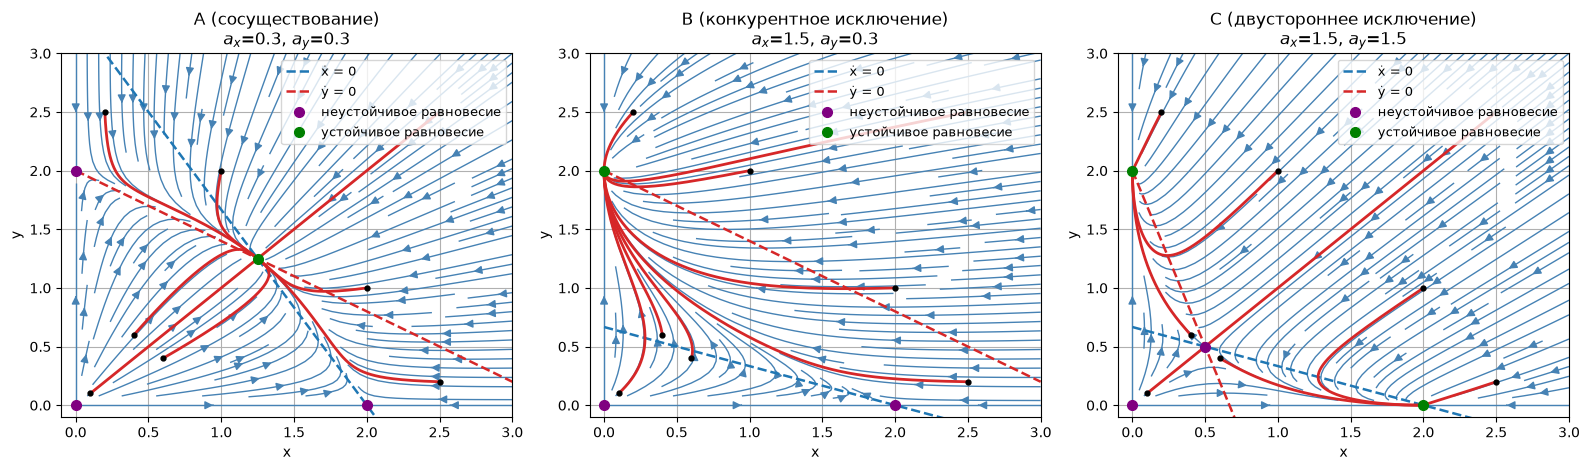

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
starts = [(0.1, 0.1), (0.2, 2.5), (2.5, 0.2), (2.5, 2.5), (1.0, 2.0), (2.0, 1.0), (0.6, 0.4), (0.4, 0.6)]
g = np.linspace(0, 3, 25)
XX, YY = np.meshgrid(g, g)

for ax_, (name, (axx, ayy)) in zip(axs, cases.items()):
    U = XX*(kx - bx*XX - axx*YY); W = YY*(ky - by*YY - ayy*XX)
    ax_.streamplot(XX, YY, U, W, color='steelblue', density=1.3, linewidth=1.0, arrowsize=1.2)
    # изоклины нулевого роста
    xl = np.linspace(0, 3, 100)
    ax_.plot(xl, (kx - bx*xl)/axx, '--', color='#1f77b4', lw=1.8, label='ẋ = 0')
    ax_.plot(xl, (ky - ayy*xl)/by, '--', color='#d62728', lw=1.8, label='ẏ = 0')
    for s0 in starts:
        _, s = integrate(s0, axx, ayy)
        ax_.plot(s[:, 0], s[:, 1], color='#d62728', lw=2.0)
        ax_.plot(*s0, '.', color='black', ms=7)
    for (X, Y) in equilibria(axx, ayy):
        if X < -1e-9 or Y < -1e-9: continue
        st = classify(np.linalg.eigvals(jac2(X, Y, axx, ayy)))
        if st == 'устойчивая':
            ax_.plot(X, Y, '.', color='green', ms=14, label='устойчивое равновесие')
        else:
            ax_.plot(X, Y, '.', color='purple', ms=14, label='неустойчивое равновесие')
    ax_.set_xlim(-0.1, 3); ax_.set_ylim(-0.1, 3)
    ax_.set_xlabel('x'); ax_.set_ylabel('y'); ax_.set_title(f'{name}\n$a_x$={axx}, $a_y$={ayy}')
    h_, l_ = ax_.get_legend_handles_labels()
    uniq = dict(zip(l_, h_)); ax_.legend(uniq.values(), uniq.keys(), loc='upper right', fontsize=9)
    ax_.grid(True)
plt.tight_layout(); plt.show()

**Выводы по фазовым портретам.**
- **Случай A.** Единственное устойчивое равновесие — внутренняя точка $(1.25;\,1.25)$: оба вида сосуществуют. Точки $(0,0)$, $(2,0)$, $(0,2)$ — неустойчивы (источник и два седла).
- **Случай B.** Внутренней точки в первом квадранте нет (она получается с отрицательной координатой). Устойчиво только равновесие $(0;\,2)$ — вид $x$ вымирает, побеждает $y$ (он слабо подавляется: $a_y=0.3$, а $x$ сильно подавляется: $a_x=1.5$). Точка $(2;0)$ — седло.
- **Случай C.** Внутренняя точка $(0.5;\,0.5)$ — **седло**, а равновесия $(2;0)$ и $(0;2)$ оба устойчивы. Исход зависит от начальных условий: побеждает тот вид, который изначально сильнее (сепаратриса — седловая траектория, идущая по диагонали $x=y$).

### Правило Гаузе: сосуществование возможно при $b_xb_y>a_xa_y$

In [8]:
print(f'{"Случай":32s} {"bx*by":>7s} {"ax*ay":>7s}  Гаузе: сосуществование?')
for name, (axx, ayy) in cases.items():
    L, R = bx*by, axx*ayy
    print(f'{name:32s} {L:7.3f} {R:7.3f}  {"да (bxby > axay)" if L > R else "нет (bxby < axay)"}')

Случай                             bx*by   ax*ay  Гаузе: сосуществование?
A (сосуществование)                0.250   0.090  да (bxby > axay)
B (конкурентное исключение)        0.250   0.450  нет (bxby < axay)
C (двустороннее исключение)        0.250   2.250  нет (bxby < axay)


**Вывод.** Правило Гаузе согласуется с результатами: в случае A $0.25>0.09$ — есть устойчивое сосуществование; в случаях B и C $0.25<0.45$ и $0.25<2.25$ — устойчивого сосуществования нет (в B побеждает один вид, в C исход определяется начальными условиями).

### Графики $x(t)$, $y(t)$

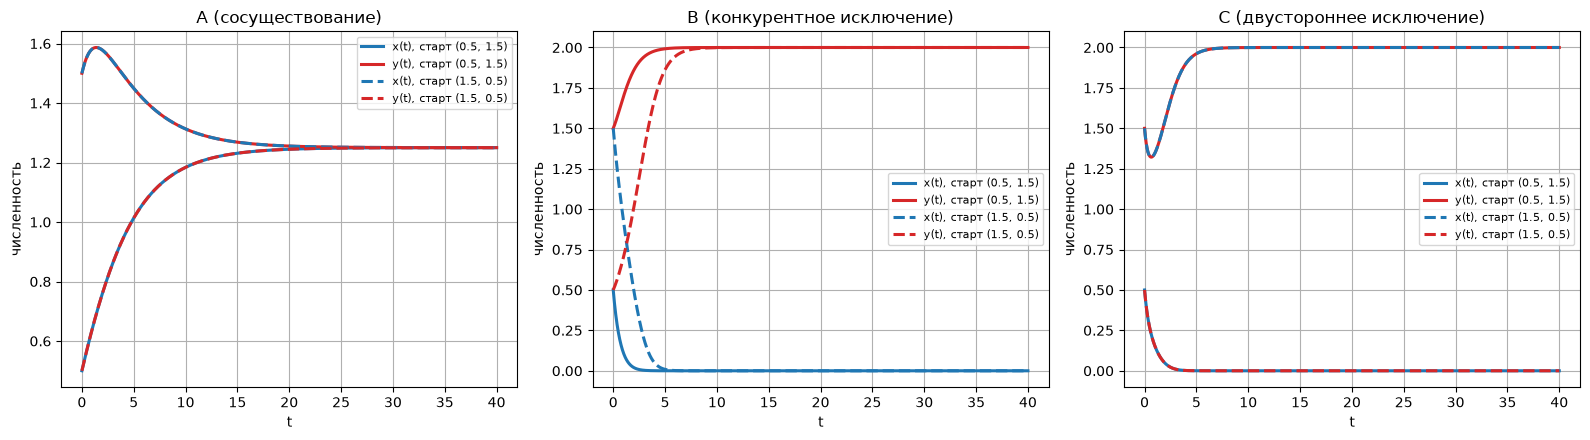

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
ics = [(0.5, 1.5), (1.5, 0.5)]     # две разные начальные точки
for ax_, (name, (axx, ayy)) in zip(axs, cases.items()):
    for j, s0 in enumerate(ics):
        tt, s = integrate(s0, axx, ayy)
        ls = '-' if j == 0 else '--'
        ax_.plot(tt, s[:, 0], ls, color='#1f77b4', lw=2.2, label=f'x(t), старт {s0}')
        ax_.plot(tt, s[:, 1], ls, color='#d62728', lw=2.2, label=f'y(t), старт {s0}')
    ax_.set_xlabel('t')
    ax_.set_ylabel('численность')
    ax_.set_title(name)
    ax_.legend(fontsize=8)
    ax_.grid(True)
plt.tight_layout(); plt.show()

**Вывод.** A: при любом старте оба вида выходят на одно и то же значение $1.25$. B: $x\to0$, $y\to2$ при обоих стартах. C: результат зависит от старта — при $(0.5;1.5)$ побеждает $y$, при $(1.5;0.5)$ побеждает $x$ (бистабильность).

## Задание 3. Логистическое отображение

$$x_{n+1}=\lambda x_n(1-x_n),\qquad x_0=0.2$$

### 1. Паутинные диаграммы

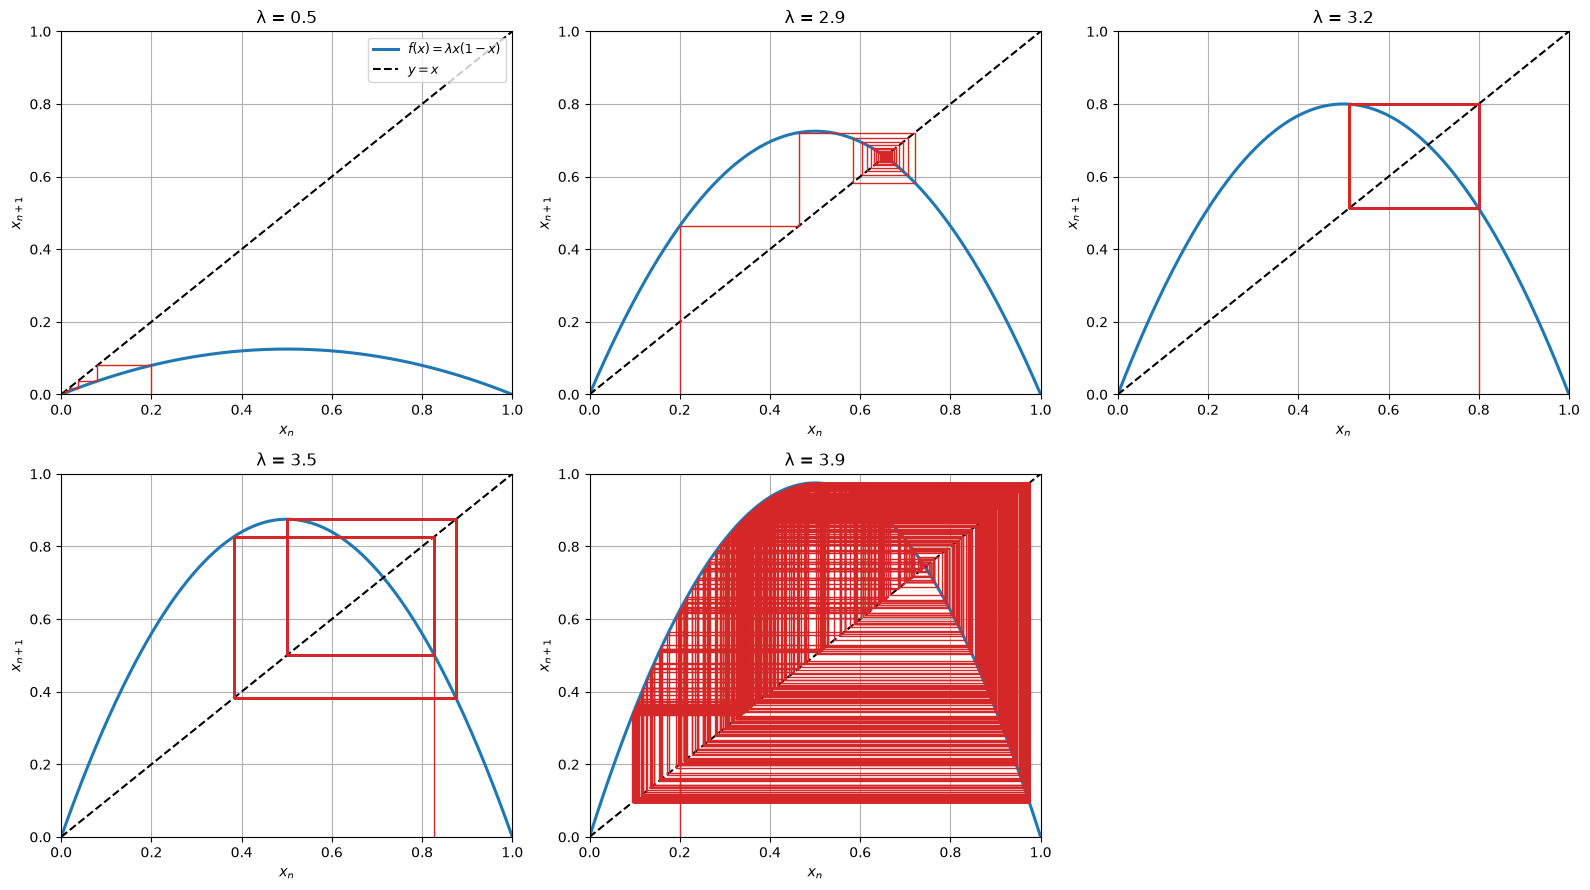

λ = 0.5: период = 1, точки = [0.]
λ = 2.9: период = 1, точки = [0.6552]
λ = 3.2: период = 2, точки = [0.513  0.7995]
λ = 3.5: период = 4, точки = [0.3828 0.5009 0.8269 0.875 ]
λ = 3.9: период = None, точки = [0.1685 0.2687 0.5464 0.5721 0.6984 0.7663 0.8214 0.9548]
Неподвижная точка при λ = 2.9: x* = 1 - 1/λ = 0.6552


In [ ]:
def f(x, lam):
    return lam*x*(1 - x)

x_start = 0.2

def cobweb(ax_, lam, skip, steps):
    xx = x_start
    for _ in range(skip):            # отбрасываем переходный процесс
        xx = f(xx, lam)
    xs = np.linspace(0, 1, 400)
    ax_.plot(xs, f(xs, lam), color='#1f77b4', lw=2.2, label='$f(x)=\\lambda x(1-x)$')
    ax_.plot(xs, xs, 'k--', lw=1.5, label='$y=x$')
    px, py = [xx], [0]
    for _ in range(steps):
        fx = f(xx, lam)
        px += [xx, fx]; py += [fx, fx]
        xx = fx
    ax_.plot(px, py, color='#d62728', lw=1.0)
    ax_.set_xlim(0, 1); ax_.set_ylim(0, 1)
    ax_.set_xlabel('$x_n$'); ax_.set_ylabel('$x_{n+1}$')
    ax_.set_title(f'λ = {lam}')
    ax_.grid(True)

# (λ, сколько итераций пропустить, сколько шагов рисовать)
params = [(0.5, 0, 30), (2.9, 0, 60), (3.2, 200, 60), (3.5, 200, 60), (3.9, 0, 400)]
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for ax_, (lam, sk, st) in zip(axs.ravel(), params):
    cobweb(ax_, lam, 0, st)
axs[0, 0].legend(loc='upper right', fontsize=9)
axs[1, 2].axis('off')
plt.tight_layout(); plt.show()

def attractor(lam, x0=x_start, n0=2000, maxp=64):
    xx = x0
    for _ in range(n0): xx = f(xx, lam)
    orb = [xx]
    for _ in range(maxp):
        orb.append(f(orb[-1], lam))
    for p in range(1, maxp + 1):
        if abs(orb[p] - orb[0]) < 1e-7:
            return p, np.sort(orb[:p])
    return None, np.sort(orb[:8])

for lam in [0.5, 2.9, 3.2, 3.5, 3.9]:
    p, pts = attractor(lam)
    print(f'λ = {lam}: период = {p}, точки = {np.round(pts, 4)}')
print('Неподвижная точка при λ = 2.9: x* = 1 - 1/λ =', round(1 - 1/2.9, 4))

**Выводы.**
- **λ = 0.5.** Траектория «лесенкой» сходится к $x^*=0$ (при $\lambda<1$ единственная неподвижная точка — нуль, устойчивая).
- **λ = 2.9.** Затухающие колебания, сходимость к $x^*=1-1/\lambda\approx0.655$ (устойчива, т.к. $|f'(x^*)|=|2-\lambda|=0.9<1$).
- **λ = 3.2.** Неподвижная точка потеряла устойчивость ($|f'|=1.2>1$), возник устойчивый цикл периода 2 между $\approx0.513$ и $\approx0.799$.
- **λ = 3.5.** Цикл периода 4 (четыре точки на прямоугольнике из «паутины»).
- **λ = 3.9.** Хаос: траектория непериодична и заполняет почти весь отрезок значений.

### 2–3. Бифуркационная диаграмма

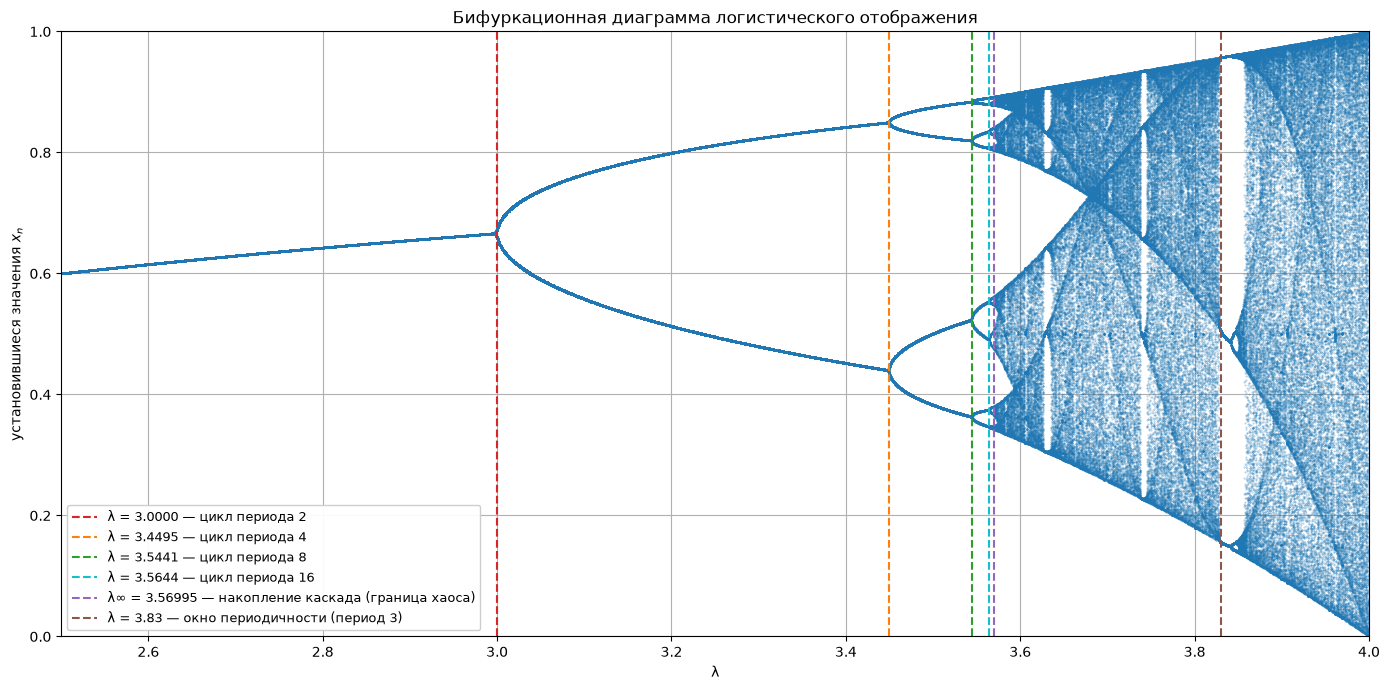

In [11]:
lams = np.linspace(2.5, 4.0, 3000)       # 3000 значений λ (≥ 1000)
n0, Nkeep = 1000, 200                    # отбрасываем n0 итераций, рисуем следующие N
xx = np.full_like(lams, 0.5)
for _ in range(n0):
    xx = f(xx, lams)
Xs = np.empty((Nkeep, lams.size))
for i in range(Nkeep):
    xx = f(xx, lams)
    Xs[i] = xx

fig, ax_ = plt.subplots(figsize=(14, 7))
ax_.plot(np.tile(lams, (Nkeep, 1)).ravel(), Xs.ravel(), '.', color='#1f77b4', ms=0.8, alpha=0.4)

events = [(3.0000,  'tab:red',    'λ = 3.0000 — цикл периода 2'),
          (3.4495,  'tab:orange', 'λ = 3.4495 — цикл периода 4'),
          (3.5441,  'tab:green',  'λ = 3.5441 — цикл периода 8'),
          (3.5644,  'tab:cyan',   'λ = 3.5644 — цикл периода 16'),
          (3.56995, 'tab:purple', 'λ∞ = 3.56995 — накопление каскада (граница хаоса)'),
          (3.83,    'tab:brown',  'λ = 3.83 — окно периодичности (период 3)')]
for lam_e, col, lab in events:
    ax_.axvline(lam_e, color=col, lw=1.5, ls='--', label=lab)
ax_.set_xlabel('λ'); ax_.set_ylabel('установившиеся значения $x_n$')
ax_.set_title('Бифуркационная диаграмма логистического отображения')
ax_.set_xlim(2.5, 4.0)
ax_.set_ylim(0, 1)
ax_.grid(True)
ax_.legend(loc='lower left', fontsize=9, framealpha=0.95)
plt.tight_layout(); plt.show()

In [12]:
# Оценка постоянной Фейгенбаума по отмеченным значениям
lam_b = [3.0, 3.4495, 3.5441, 3.5644]
for i in range(len(lam_b) - 2):
    d = (lam_b[i+1] - lam_b[i]) / (lam_b[i+2] - lam_b[i+1])
    print(f'δ_{i+1} = ({lam_b[i+1]} - {lam_b[i]}) / ({lam_b[i+2]} - {lam_b[i+1]}) = {d:.3f}')
print('Табличное значение δ ≈ 4.6692')

δ_1 = (3.4495 - 3.0) / (3.5441 - 3.4495) = 4.752
δ_2 = (3.5441 - 3.4495) / (3.5644 - 3.5441) = 4.660
Табличное значение δ ≈ 4.6692


**Вывод.** При росте λ неподвижная точка теряет устойчивость при $\lambda=3$, далее следует каскад удвоения периода ($2\to4\to8\to16\to\dots$), причём интервалы между бифуркациями быстро сокращаются, их отношение стремится к постоянной Фейгенбаума $\delta\approx4.669$ (оценки выше: $\approx4.75$ и $\approx4.66$). После $\lambda_\infty\approx3.56995$ начинается хаос, внутри которого встречаются окна периодичности (например, цикл периода 3 при $\lambda\approx3.83$).

### 4. Чувствительность к начальным данным ($\lambda=3.9$)

Начальное расхождение: 1.0e-05
Расхождение впервые превышает 0.1 при n = 18 (|Δ| = 0.138)


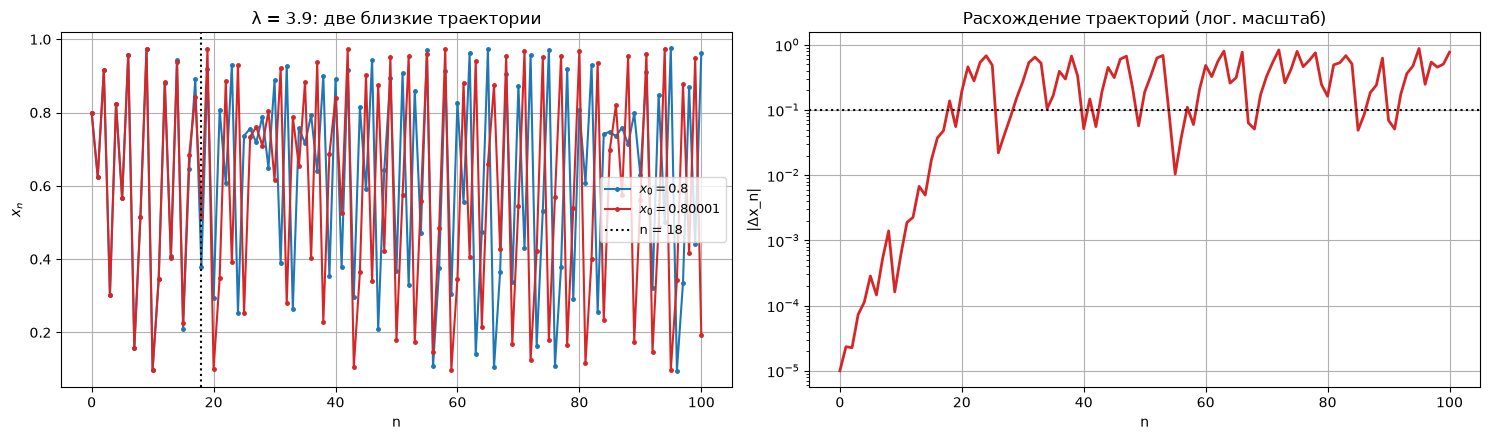

In [13]:
lam = 3.9
Nit = 100
xa = np.empty(Nit + 1); xb = np.empty(Nit + 1)
xa[0], xb[0] = 0.8, 0.80001
for i in range(Nit):
    xa[i+1] = f(xa[i], lam)
    xb[i+1] = f(xb[i], lam)
diff = np.abs(xa - xb)
n_div = int(np.argmax(diff > 0.1))
print(f'Начальное расхождение: {diff[0]:.1e}')
print(f'Расхождение впервые превышает 0.1 при n = {n_div} (|Δ| = {diff[n_div]:.3f})')

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].plot(range(Nit + 1), xa, '.-', color='#1f77b4', ms=5, lw=1.5, label='$x_0=0.8$')
axs[0].plot(range(Nit + 1), xb, '.-', color='#d62728', ms=5, lw=1.5, label='$x_0=0.80001$')
axs[0].axvline(n_div, color='k', ls=':', label=f'n = {n_div}')
axs[0].set_xlabel('n')
axs[0].set_ylabel('$x_n$')
axs[0].set_title('λ = 3.9: две близкие траектории')
axs[0].legend(fontsize=9)
axs[0].grid(True)
axs[1].semilogy(range(Nit + 1), diff + 1e-18, color='#d62728', lw=2.0)
axs[1].axhline(0.1, color='k', ls=':')
axs[1].set_xlabel('n')
axs[1].set_ylabel('|Δx_n|')
axs[1].set_title('Расхождение траекторий (лог. масштаб)')
axs[1].grid(True)
plt.tight_layout(); plt.show()

**Вывод.** Начальные данные различаются всего на $10^{-5}$, но уже через **18 итераций** расхождение траекторий превышает $0.1$. Первые итерации траектории неотличимы, затем различие растёт примерно экспоненциально (прямая на лог. графике), и далее траектории ведут себя совершенно по-разному. Следовательно, детерминированная система при $\lambda=3.9$ непредсказуема на практике: любая неточность в начальном условии (измерения, округления) быстро разрушает прогноз — это и есть чувствительность к начальным данным, признак детерминированного хаоса.